# 02 – Exploratory analysis

Exploratory analysis of NDMI anomalies, SPI and irrigated fields during the 2022–24 drought.


In [1]:
import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt

from src.paths import PROCESSED

Load the saved data cube

In [2]:
cube = xr.open_zarr(PROCESSED / "cube.zarr").load()

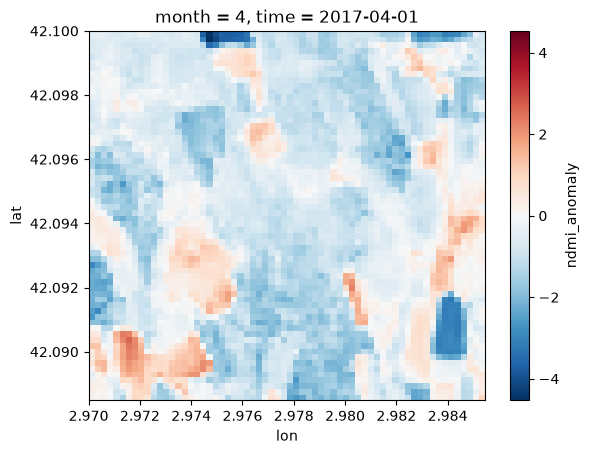

In [3]:
# read data
tile = cube.isel(lat = slice(0, 64), lon = slice(0, 64), time = 0).load()
# july = cube.ndmi_anomaly.sel(time = "2023-07-01").load()
tile.ndmi_anomaly.plot()


NDMI anomaly maps for summer 2021 against summer 2023

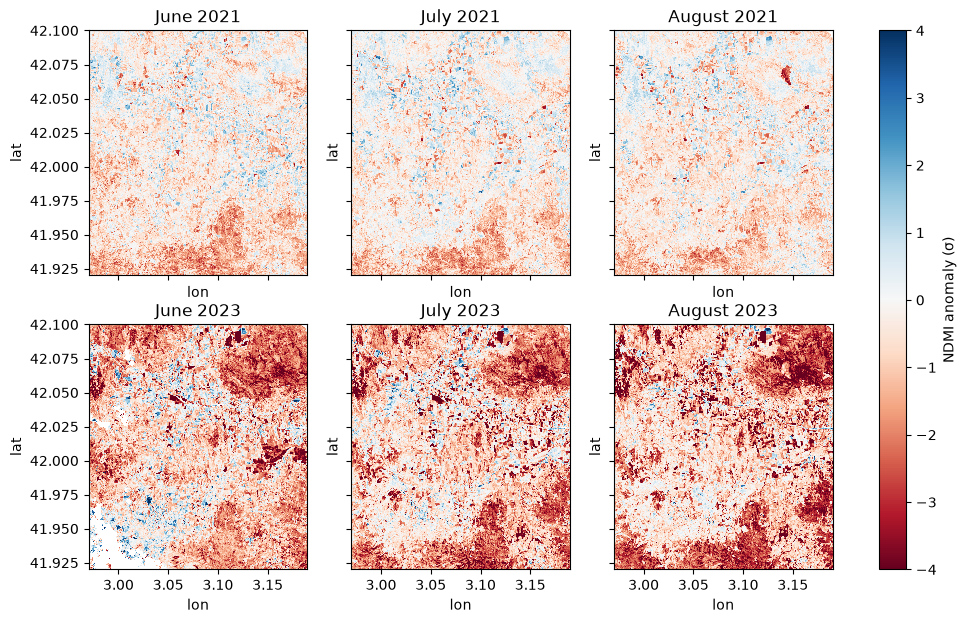

In [4]:

fig, axes = plt.subplots(2, 3, figsize = (12, 7), sharex = True, sharey = True)
months = ['June', 'July', 'August']

for i, year in enumerate([2021, 2023]):
    for j, month in enumerate([6, 7, 8]):
        im = cube.ndmi_anomaly.sel(time = (cube.time.dt.year == year) & (cube.time.dt.month == month)).plot(ax = axes[i, j], 
            add_colorbar = False, vmin = -4, vmax = 4, cmap = "RdBu")
        axes[i, j].set_title(months[j] + ' ' + str(year))
# plt.tight_layout()

fig.colorbar(im, ax = axes, label = "NDMI anomaly (σ)")

SPI against the mean NDMI anomaly over the whole area

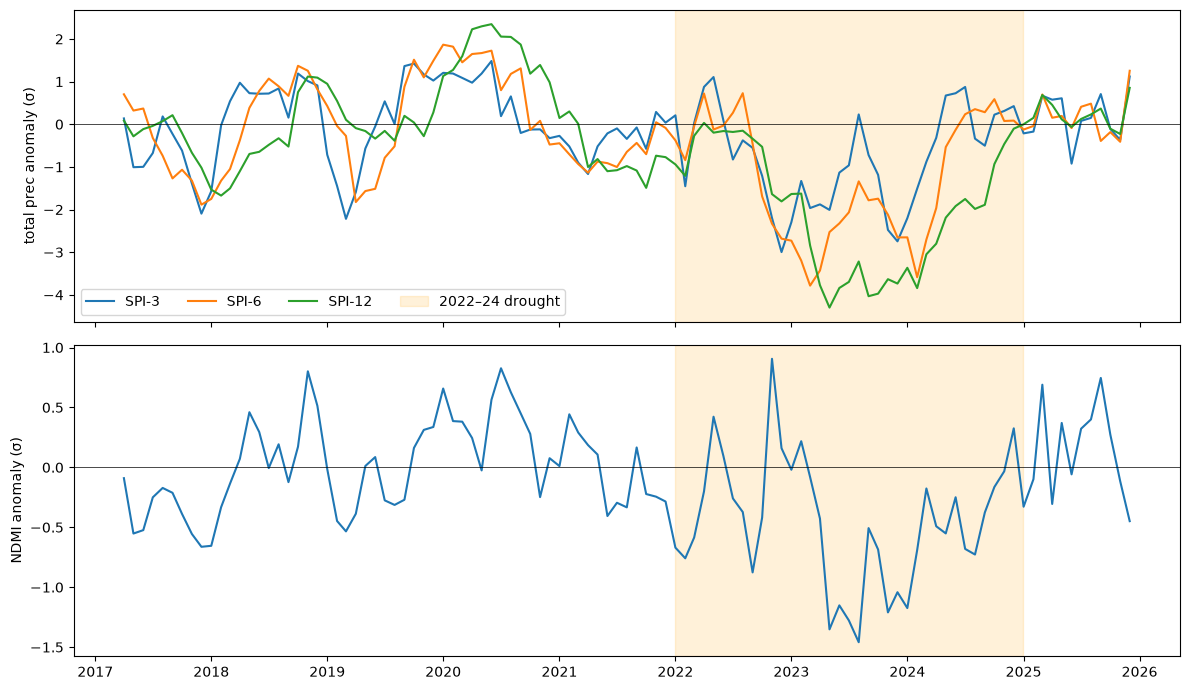

In [5]:
fig, axes = plt.subplots(2, 1, figsize = (12, 7), sharex = True)
cube.spi3.mean(dim = ["lat", "lon"]).plot(ax = axes[0], label = 'SPI-3')
cube.spi6.mean(dim = ["lat", "lon"]).plot(ax = axes[0], label = 'SPI-6')
cube.spi12.mean(dim = ["lat", "lon"]).plot(ax = axes[0], label = 'SPI-12')
cube.ndmi_anomaly.mean(dim = ["lat", "lon"]).plot(ax = axes[1], label = 'ndmi anomaly')

for ax in axes:
    ax.axvspan(pd.Timestamp("2022-01-01"), pd.Timestamp("2024-12-31"), color = "orange", alpha = 0.15, label = "2022–24 drought")
    ax.set_xlabel("")


axes[0].set_ylabel("total prec anomaly (σ)")
axes[1].set_ylabel("NDMI anomaly (σ)")
axes[0].axhline(0, color = "k", lw = 0.5)
axes[1].axhline(0, color = "k", lw = 0.5)
axes[0].legend(ncol = 5)
plt.tight_layout()

Correlation between NDMI and rain anomaly at N months lag

In [6]:
# time series of means over the whole area
df = pd.DataFrame()
df['ndmi_ts'] = cube.ndmi_anomaly.mean(["lat", "lon"])
for col in ['spi3', 'spi6', 'spi12']:
    df[col] = cube[col].mean(["lat", "lon"])

df.head()

,ndmi_ts,spi3,spi6,spi12
0,-0.090120,0.136874,0.702335,0.085202
1,-0.552160,-1.006776,0.321261,-0.282963
2,-0.523716,-0.998345,0.369117,-0.113490
3,-0.250093,-0.674639,-0.321459,-0.037788
4,-0.171656,0.183432,-0.738276,0.072757


Text(0.5, 0, 'lag months')

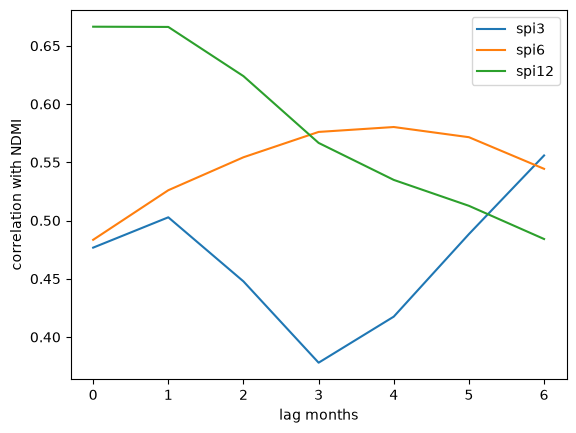

In [7]:
df.ndmi_ts.corr(df.spi3.shift(1))
lags = range(0, 7)
corr = pd.DataFrame(columns = ['spi3', 'spi6', 'spi12'])
for col in corr.columns:
    corr[col] = [df.ndmi_ts.corr(df[col].shift(L)) for L in lags]

corr.plot()
plt.legend()
plt.ylabel('correlation with NDMI')
plt.xlabel('lag months')

How did the ndmi median and its anomaly evolve during the whole period? Let's plot, for each type of land cover, the evolution of their means over the whole area

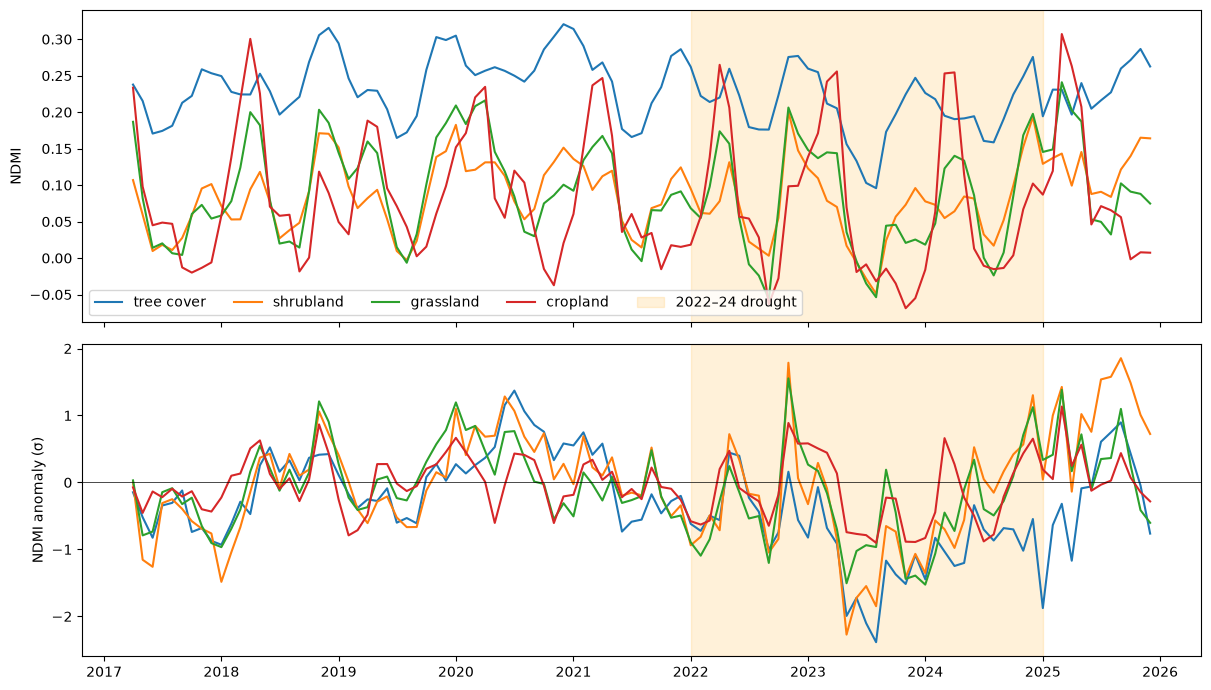

In [8]:
world_classess = {10: "tree cover", 20: "shrubland", 30: "grassland", 40: "cropland"}
fig, axes = plt.subplots(2, 1, figsize = (12, 7), sharex = True)

for cover_type in world_classess.keys():
    lc_condition = cube["landcover"] == cover_type
    cube.ndmi_median.where(lc_condition).mean(dim = ["lat", "lon"]).plot(ax = axes[0], label = world_classess[cover_type])
    cube.ndmi_anomaly.where(lc_condition).mean(dim = ["lat", "lon"]).plot(ax = axes[1], label = world_classess[cover_type])


for ax in axes:
    ax.axvspan(pd.Timestamp("2022-01-01"), pd.Timestamp("2024-12-31"), color = "orange", alpha = 0.15, label = "2022–24 drought")
    ax.set_xlabel("")


axes[0].set_ylabel("NDMI")
axes[1].set_ylabel("NDMI anomaly (σ)")
axes[1].axhline(0, color = "k", lw = 0.5)
axes[0].legend(ncol = 5)
plt.tight_layout()

let us compare these same metrics for irrigated and non-irrigated croplands only

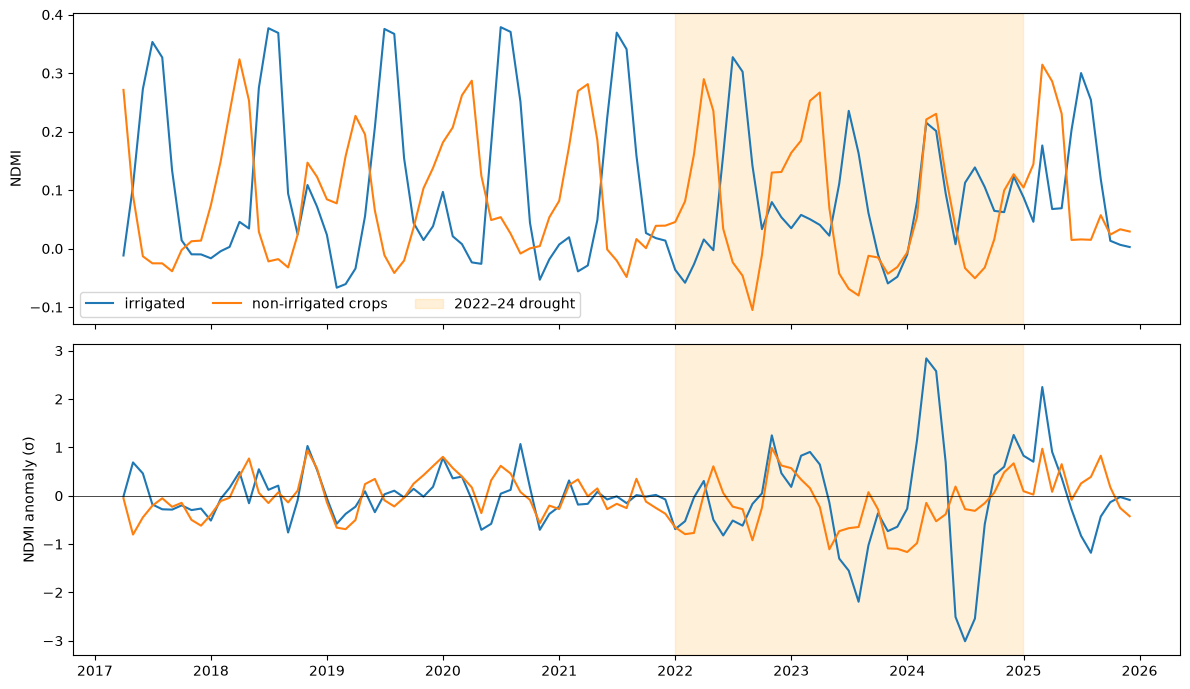

In [9]:
fig, axes = plt.subplots(2, 1, figsize = (12, 7), sharex = True)

masks = {"irrigated" : (cube.irrigated == 1),
         "non-irrigated crops": (cube.irrigated == 0) & cube.landcover.isin([30, 40])}

for name, mask in masks.items():
    cube.ndmi_median.where(mask).mean(["lat", "lon"]).plot(ax = axes[0], label = name)
    cube.ndmi_anomaly.where(mask).mean(["lat", "lon"]).plot(ax = axes[1], label = name)


for ax in axes:
    ax.axvspan(pd.Timestamp("2022-01-01"), pd.Timestamp("2024-12-31"), color = "orange", alpha = 0.15, label = "2022–24 drought")
    ax.set_xlabel("")

axes[0].set_ylabel("NDMI")
axes[1].set_ylabel("NDMI anomaly (σ)")
axes[1].axhline(0, color = "k", lw = 0.5)
axes[0].legend(ncol = 5)
plt.tight_layout()

irrigated fields do not stay wet during the drought: maybe an irrigation restriction

compare NDMI and NDVI

In [10]:
masks = {"irrigated" : (cube.irrigated == 1),
         "non-irrigated crops": (cube.irrigated == 0) & cube.landcover.isin([30, 40]),
         "forest": cube.landcover == 10}
lags = range(-3, 4)

corr = pd.DataFrame()
corr["lag months"] = lags
for key, mask in masks.items():
    # time series for ndvi and ndmi anomalies
    ndvi_ts = cube.ndvi_anomaly.where(mask).mean(dim = ["lat", "lon"])
    ndmi_ts = cube.ndmi_anomaly.where(mask).mean(dim = ["lat", "lon"])

    # correlation at different month lags
    r = [float(xr.corr(ndvi_ts, ndmi_ts.shift(time = L))) for L in lags]
    corr[key] = np.round(r, 2)
    
corr

,lag months,irrigated,non-irrigated crops,forest
0,-3,-0.25,0.02,0.28
1,-2,0.11,0.21,0.34
2,-1,0.60,0.58,0.49
3,0,0.94,0.91,0.67
4,1,0.75,0.55,0.48
5,2,0.29,0.22,0.48
6,3,-0.21,0.01,0.29


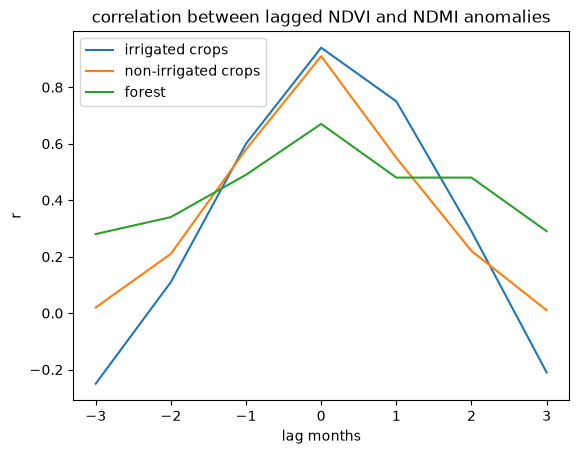

In [11]:
plt.plot(corr["lag months"], corr["irrigated"], label = 'irrigated crops')
plt.plot(corr["lag months"], corr["non-irrigated crops"], label = 'non-irrigated crops')
plt.plot(corr["lag months"], corr["forest"], label = 'forest')
plt.xlabel("lag months")
plt.ylabel("r")
plt.title("correlation between lagged NDVI and NDMI anomalies")
plt.legend()

the curve is centered at zero but assymetric, with higher values at positive lags, so NDMI comes first